# 04, modélisation

Phase 4 de CRISP-DM. Ce notebook note les trois stratégies retenues sur l'eau, l'accès à un débouché organisé et l'apport d'azote par les légumineuses, les classe pour chaque priorité de l'agriculteur, puis teste la stabilité du classement. Il appelle `moteur/criteres.py`, `moteur/cultures.py` et `moteur/rotations.py` sans calcul propre.

Aucun rendement n'est prédit. Les scores sont des comparaisons argumentées, à règles visibles, et non une solution optimale.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from moteur.criteres import (CRITERES, INDICATEURS, LIBELLES, POIDS_PAR_PRIORITE, SCENARIOS, comparer_semis,
                             contextes_du_lieu, parts_par_culture, sensibilite, tableau_evaluations, tableau_scenarios,
                             tableau_scores)
from moteur.cultures import (FENETRE_SEMIS_COTON, avec_stades_coton, mi_saisons_comparees, semis_coton,
                             variantes_duree_coton)
from moteur.lieux import LIEUX_ETUDE as LIEUX
from moteur.rotations import STRATEGIES

pd.set_option("display.precision", 3)
noms = {identifiant: lieu["nom"] for identifiant, lieu in LIEUX.items()}
contextes = {identifiant: contextes_du_lieu(identifiant) for identifiant in LIEUX}

## 1. Règles de notation

Chaque critère est une liste d'indicateurs, et son score de 0 à 5 est la moyenne de ses indicateurs disponibles. Les règles sont décrites en tête de `moteur/criteres.py`. Les clés `eau`, `revenu` et `sol` du contrat restent inchangées, seuls les libellés nomment ce que les indicateurs mesurent.

In [2]:
display(pd.DataFrame([{"clé": c, "libellé": LIBELLES[c], "indicateurs": ", ".join(f.__name__ for f in INDICATEURS[c])}
                      for c in CRITERES]))
display(pd.DataFrame({p: dict(poids) for p, poids in POIDS_PAR_PRIORITE.items()}).T)
display(pd.DataFrame(SCENARIOS).T)
display(pd.DataFrame({i: semis_coton(i) for i in LIEUX}).rename(index={"coton": "semis de référence du coton"}))
pd.DataFrame(mi_saisons_comparees(), index=["premier jour de mi-saison", "dernier jour de mi-saison"]).T

,clé,libellé,indicateurs
0,eau,eau,"couverture_du_besoin, secheresse_mi_saison"
1,revenu,accès à un débouché organisé,acces_debouche_organise
2,sol,apport d'azote par les légumineuses,apport_azote_legumineuses


,eau,revenu,sol
eau,0.6,0.2,0.2
revenu,0.2,0.6,0.2
sol,0.2,0.2,0.6


,facteur_pluie,retard_jours,semis_coton
reference,1.0,0,fenetre
pluie_moins_20_pourcent,0.8,0,fenetre
debut_retarde_de_14_jours,1.0,14,fenetre
coton_seme_au_debut_des_pluies,1.0,0,debut_des_pluies


,korhogo,bouake
semis de référence du coton,06-15,06-25


,premier jour de mi-saison,dernier jour de mi-saison
coton,81,140
maïs,56,95
sorgho,56,95
mil,41,80
arachide,61,105
niébé,51,80
soja,31,70
riz pluvial,61,120


**Constat.** L'eau a deux indicateurs calculés année par année, la part des années où la pluie IMERG du cycle couvre le besoin en eau de la culture, coefficient cultural FAO-56 fois évapotranspiration de référence, et la part des années sans séquence sèche de plus de 7 jours pendant le stade de mi-saison. Le coton est semé au milieu de la fenêtre observée par le CNRA, le 15 juin à Korhogo et le 25 juin à Bouaké, ou au début des pluies s'il survient plus tard. Les autres cultures sont semées au début des pluies. L'accès à un débouché organisé est la part des années en coton, et l'apport d'azote la part des années en légumineuse.

**Analyse.** FAO-56 situe la plus forte sensibilité au manque d'eau à la floraison et à la formation du rendement, son chapitre 8, et place la floraison au début de la mi-saison, son chapitre 5. Le seuil de 7 jours est celui de la règle de début de saison. Le semis du coton suit Gnapi et collègues, 2025, page 1575, mieux sourcé que le début des pluies, qui reste un scénario de sensibilité. L'accès à un débouché organisé repose sur Zagbaï et collègues, page 325, et pénalise mécaniquement toute rotation qui réduit le coton. L'apport d'azote repose sur Yusuf et collègues, au Nigeria. Ces deux critères sont de niveau `hypothese` et ne dépendent pas du lieu.

**Décision.** Règles validées comme approximations par le responsable, semis du CNRA retenu comme référence pour le coton. Un indicateur tiré de SMAP ou de MODIS s'ajoutera à la liste de son critère sans changer le reste.

## 2. L'eau culture par culture

Korhogo                                                 \
             annees couverture_du_besoin sans_secheresse_mi_saison   
culture                                                              
coton            25                 0.76                      0.68   
maïs             25                 0.96                      0.84   
sorgho           25                 1.00                      0.84   
mil              25                 0.92                      0.92   
arachide         25                 1.00                      0.84   
niébé            25                 0.92                      0.96   
soja             25                 0.40                      0.84   
riz pluvial      25                 0.56                      0.84   

                                                   Bouaké  \
            sequence_seche_mi_saison_mediane_jours annees   
culture                                                     
coton                                          6.0     24   
maïs                                           5.0     25   
sorgho                                         5.0     25   
mil                                            5.0     25   
arachide                                       6.0     25   
niébé                                          5.0     25   
soja                                           6.0     25   
riz pluvial                                    6.0     25   

                                                            \
            couverture_du_besoin sans_secheresse_mi_saison   
culture                                                      
coton                      0.375                     0.333   
maïs                       0.880                     0.800   
sorgho                     0.960                     0.800   
mil                        0.920                     0.840   
arachide                   0.880                     0.560   
niébé                      0.880                     0.840   
soja                       0.680                     0.840   
riz pluvial                0.280                     0.440   

                                                    
            sequence_seche_mi_saison_mediane_jours  
culture                                             
coton                                          9.0  
maïs                                           6.0  
sorgho                                         6.0  
mil                                            6.0  
arachide                                       7.0  
niébé                                          5.0  
soja                                           6.0  
riz pluvial                                    8.0

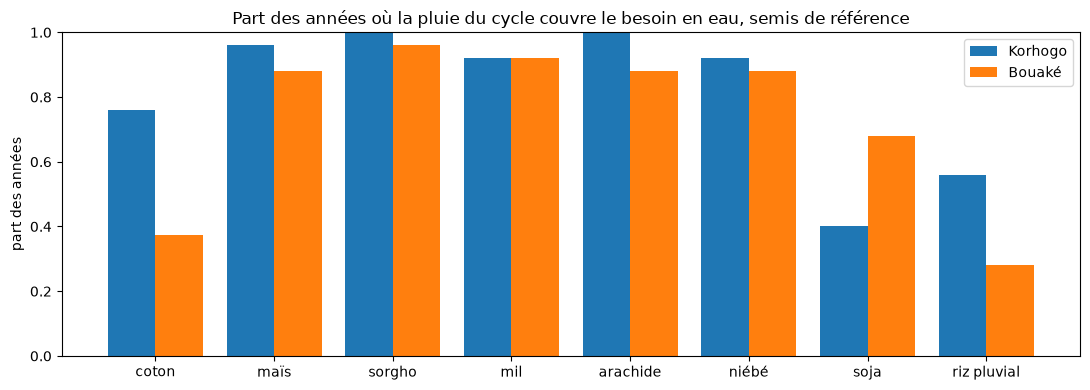

In [3]:
parts = {i: parts_par_culture(c["reference"]) for i, c in contextes.items()}
display(pd.concat({noms[i]: p for i, p in parts.items()}, axis=1))

figure, axe = plt.subplots(figsize=(11, 4))
largeur = 0.4
for decalage, couleur, (identifiant, p) in zip([-largeur / 2, largeur / 2], ["C0", "C1"], parts.items()):
    axe.bar([k + decalage for k in range(len(p))], p["couverture_du_besoin"], width=largeur, color=couleur,
            label=noms[identifiant])
axe.set(title="Part des années où la pluie du cycle couvre le besoin en eau, semis de référence", ylabel="part des années",
        ylim=(0, 1), xticks=range(len(parts["korhogo"])), xticklabels=parts["korhogo"].index)
axe.legend()
plt.tight_layout()
plt.show()

**Constat.** Semé le 25 juin à Bouaké, le coton voit sa pluie couvrir son besoin 0,375 des années seulement, et passer sa mi-saison sans séquence sèche de plus de 7 jours 0,333 des années, sur 24 années, la dernière ne finissant pas avant la fin des séries. À Korhogo, semé le 15 juin, il atteint 0,76 et 0,68. Le maïs, le sorgho et le niébé atteignent au moins 0,8 dans les deux villes pour la séquence sèche, et 0,88 pour la couverture.

**Analyse.** Avec un cycle de 195 jours, un coton semé fin juin à Bouaké finit en janvier, en pleine saison sèche, et c'est surtout ce débordement qui fait chuter sa couverture. La durée de 195 jours est tirée d'une ligne de FAO-56 établie hors d'Afrique de l'Ouest, et la section 7 montre combien ce résultat en dépend.

**Décision.** Le coton reste la culture la plus exposée au manque d'eau à Bouaké dans la référence, sous la réserve de sa durée de cycle.

## 3. Évaluations détaillées des stratégies, scénario de référence

Les colonnes bas et haut donnent, pour l'eau, l'intervalle à 90 % obtenu en rééchantillonnant les années, graine fixée.

In [4]:
for identifiant, contexte in contextes.items():
    print(noms[identifiant])
    display(tableau_evaluations(STRATEGIES, contexte["reference"]))

Korhogo


,strategie,critere,indicateur,valeur,bas,haut,unite,score,niveau,source
0,coton_mais,eau,couverture_du_besoin,0.860,0.780,0.940,part des années,4.300,calcule,"FAO56_T11_T12, IMERG, POWER"
1,coton_mais,eau,secheresse_mi_saison,0.760,0.660,0.860,part des années,3.800,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
2,coton_mais,revenu,acces_debouche_organise,0.500,NaN,NaN,part des années,2.500,hypothese,ZAGBAI2006
3,coton_mais,sol,apport_azote_legumineuses,0.000,NaN,NaN,part des années,0.000,hypothese,YUSUF2009
4,coton_niebe_mais,eau,couverture_du_besoin,0.880,0.813,0.933,part des années,4.400,calcule,"FAO56_T11_T12, IMERG, POWER"
5,coton_niebe_mais,eau,secheresse_mi_saison,0.827,0.747,0.893,part des années,4.133,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
6,coton_niebe_mais,revenu,acces_debouche_organise,0.333,NaN,NaN,part des années,1.667,hypothese,ZAGBAI2006
7,coton_niebe_mais,sol,apport_azote_legumineuses,0.333,NaN,NaN,part des années,1.667,hypothese,YUSUF2009
8,sorgho_niebe,eau,couverture_du_besoin,0.960,0.920,1.000,part des années,4.800,calcule,"FAO56_T11_T12, IMERG, POWER"
9,sorgho_niebe,eau,secheresse_mi_saison,0.900,0.820,0.980,part des années,4.500,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"


Bouaké


,strategie,critere,indicateur,valeur,bas,haut,unite,score,niveau,source
0,coton_mais,eau,couverture_du_besoin,0.625,0.521,0.729,part des années,3.125,calcule,"FAO56_T11_T12, IMERG, POWER"
1,coton_mais,eau,secheresse_mi_saison,0.562,0.458,0.667,part des années,2.812,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
2,coton_mais,revenu,acces_debouche_organise,0.500,NaN,NaN,part des années,2.500,hypothese,ZAGBAI2006
3,coton_mais,sol,apport_azote_legumineuses,0.000,NaN,NaN,part des années,0.000,hypothese,YUSUF2009
4,coton_niebe_mais,eau,couverture_du_besoin,0.708,0.597,0.806,part des années,3.542,calcule,"FAO56_T11_T12, IMERG, POWER"
5,coton_niebe_mais,eau,secheresse_mi_saison,0.653,0.569,0.736,part des années,3.264,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
6,coton_niebe_mais,revenu,acces_debouche_organise,0.333,NaN,NaN,part des années,1.667,hypothese,ZAGBAI2006
7,coton_niebe_mais,sol,apport_azote_legumineuses,0.333,NaN,NaN,part des années,1.667,hypothese,YUSUF2009
8,sorgho_niebe,eau,couverture_du_besoin,0.920,0.840,0.980,part des années,4.600,calcule,"FAO56_T11_T12, IMERG, POWER"
9,sorgho_niebe,eau,secheresse_mi_saison,0.820,0.700,0.920,part des années,4.100,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"


**Constat.** À Korhogo, la couverture du besoin vaut 0,86 pour coton puis maïs, de 0,78 à 0,94, 0,88 pour coton, niébé puis maïs et 0,96 pour sorgho puis niébé, de 0,92 à 1. À Bouaké, elle vaut 0,625 pour coton puis maïs, de 0,521 à 0,729, 0,708 pour coton, niébé puis maïs et 0,92 pour sorgho puis niébé, de 0,84 à 0,98. La part des années sans séquence sèche à la mi-saison suit le même ordre, de 0,76 à 0,9 à Korhogo et de 0,562 à 0,82 à Bouaké.

**Analyse.** L'écart entre stratégies est bien plus net à Bouaké, où les intervalles de sorgho puis niébé et de coton puis maïs ne se recoupent pas. À Korhogo, les intervalles se touchent presque, l'écart y est donc plus fragile.

**Décision.** L'outil montre ces intervalles avec chaque score d'eau.

## 4. Scores et classement pour chaque priorité

Korhogo, priorité eau


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.650,0.000,2.500,False,3.290,1
coton_niebe_mais,4.267,1.667,1.667,False,3.227,2
coton_mais,4.050,2.500,0.000,True,2.930,3


Korhogo, priorité revenu


,eau,revenu,sol,actuelle,note,rang
coton_mais,4.050,2.500,0.000,True,2.310,1
coton_niebe_mais,4.267,1.667,1.667,False,2.187,2
sorgho_niebe,4.650,0.000,2.500,False,1.430,3


Korhogo, priorité sol


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.650,0.000,2.500,False,2.430,1
coton_niebe_mais,4.267,1.667,1.667,False,2.187,2
coton_mais,4.050,2.500,0.000,True,1.310,3


... (2 outputs left out)

Bouaké, priorité revenu


,eau,revenu,sol,actuelle,note,rang
coton_mais,2.969,2.500,0.000,True,2.094,1
coton_niebe_mais,3.403,1.667,1.667,False,2.014,2
sorgho_niebe,4.350,0.000,2.500,False,1.370,3


Bouaké, priorité sol


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.350,0.000,2.500,False,2.370,1
coton_niebe_mais,3.403,1.667,1.667,False,2.014,2
coton_mais,2.969,2.500,0.000,True,1.094,3


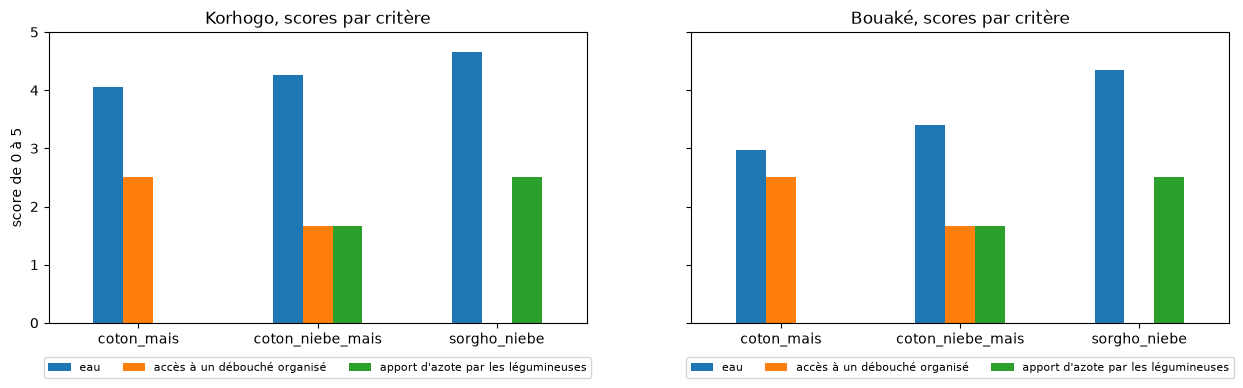

In [5]:
for identifiant, contexte in contextes.items():
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        print(f"{noms[identifiant]}, priorité {priorite}")
        display(tableau_scores(STRATEGIES, contexte["reference"], poids))

figure, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axe, (identifiant, contexte) in zip(axes, contextes.items()):
    table = tableau_scores(STRATEGIES, contexte["reference"], POIDS_PAR_PRIORITE["eau"]).sort_index()
    table[list(CRITERES)].rename(columns=LIBELLES).plot.bar(ax=axe, rot=0)
    axe.set(title=f"{noms[identifiant]}, scores par critère", ylabel="score de 0 à 5", ylim=(0, 5))
    axe.legend(fontsize=8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**Constat.** Les deux villes reçoivent le même classement pour les trois priorités. Pour l'eau, sorgho puis niébé est premier, note 3,29 à Korhogo et 3,11 à Bouaké, devant coton, niébé puis maïs, 3,227 et 2,708, et coton puis maïs, 2,93 et 2,281. Coton puis maïs est premier pour le débouché, sorgho puis niébé pour l'azote. Les scores d'eau diffèrent pourtant nettement, de 4,05 à 4,65 à Korhogo et de 2,969 à 4,35 à Bouaké.

**Analyse.** Les données IMERG distinguent bien les deux villes en valeur, Bouaké étant plus exposée au manque d'eau, mais l'ordre des stratégies y est le même. Pour le débouché et l'azote, l'identité est attendue, ces critères ne dépendant pas du lieu. À Korhogo, l'écart de note entre les deux premières stratégies pour l'eau n'est que de 0,063.

**Décision.** Le résultat est rapporté tel quel. Les deux villes ne se distinguent pas par le classement, mais par l'ampleur du risque d'eau, ce que l'outil montre.

## 5. Sensibilité

Pluie réduite de 20 %, début de saison retardé de 14 jours, et coton semé au début des pluies au lieu de la fenêtre du CNRA.

In [6]:
for identifiant, contexte in contextes.items():
    print(noms[identifiant])
    valeurs = tableau_scenarios(STRATEGIES, contexte)
    display(valeurs.loc[valeurs.index.get_level_values("indicateur").isin(["couverture_du_besoin", "secheresse_mi_saison"])])
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        rangs, stable, changeants = sensibilite(STRATEGIES, contexte, poids)
        print(f"priorité {priorite}, classement stable {stable}, scénarios qui le changent {changeants}")
        display(rangs)

Korhogo


reference  pluie_moins_20_pourcent  \
strategie        indicateur                                                 
coton_mais       couverture_du_besoin      0.860                     0.58   
                 secheresse_mi_saison      0.760                     0.76   
coton_niebe_mais couverture_du_besoin      0.880                     0.60   
                 secheresse_mi_saison      0.827                     0.80   
sorgho_niebe     couverture_du_besoin      0.960                     0.78   
                 secheresse_mi_saison      0.900                     0.88   

                                       debut_retarde_de_14_jours  \
strategie        indicateur                                        
coton_mais       couverture_du_besoin                      0.880   
                 secheresse_mi_saison                      0.780   
coton_niebe_mais couverture_du_besoin                      0.920   
                 secheresse_mi_saison                      0.813   
sorgho_niebe     couverture_du_besoin                      1.000   
                 secheresse_mi_saison                      0.880   

                                       coton_seme_au_debut_des_pluies  
strategie        indicateur                                            
coton_mais       couverture_du_besoin                           0.980  
                 secheresse_mi_saison                           0.860  
coton_niebe_mais couverture_du_besoin                           0.960  
                 secheresse_mi_saison                           0.893  
sorgho_niebe     couverture_du_besoin                           0.960  
                 secheresse_mi_saison                           0.900

priorité eau, classement stable False, scénarios qui le changent ['coton_seme_au_debut_des_pluies']


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours,coton_seme_au_debut_des_pluies
sorgho_niebe,1,1,1,2
coton_niebe_mais,2,2,2,1
coton_mais,3,3,3,3


priorité revenu, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours,coton_seme_au_debut_des_pluies
coton_mais,1,1,1,1
coton_niebe_mais,2,2,2,2
sorgho_niebe,3,3,3,3


... (6 outputs left out)

priorité revenu, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours,coton_seme_au_debut_des_pluies
coton_mais,1,1,1,1
coton_niebe_mais,2,2,2,2
sorgho_niebe,3,3,3,3


priorité sol, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours,coton_seme_au_debut_des_pluies
sorgho_niebe,1,1,1,1
coton_niebe_mais,2,2,2,2
coton_mais,3,3,3,3


**Constat.** À Bouaké, le classement ne change dans aucun scénario, pour aucune priorité. À Korhogo, pour la priorité eau, le semis du coton au début des pluies fait passer coton, niébé puis maïs devant sorgho puis niébé. Une pluie réduite de 20 % fait tomber la couverture du besoin de coton puis maïs de 0,86 à 0,58 à Korhogo et de 0,625 à 0,354 à Bouaké, sans changer l'ordre.

**Analyse.** Le classement de Korhogo pour l'eau dépend de la date de semis retenue pour le coton, parce que les deux premières stratégies y sont presque à égalité. Celui de Bouaké est robuste aux quatre scénarios.

**Décision.** L'outil déclare le classement de Korhogo instable pour la priorité eau et nomme le scénario du semis au début des pluies, ce qu'écrivent aussi les limites et `docs/decisions.md`.

## 6. Position du semis du coton dans la fenêtre du CNRA

Le coton est semé au début, au milieu ou à la fin de la fenêtre où sèment la plupart des producteurs selon Gnapi et collègues, 2025, page 1575, ou au début des pluies.

In [7]:
display(pd.DataFrame(FENETRE_SEMIS_COTON, index=["début de fenêtre", "fin de fenêtre"]))
for identifiant in LIEUX:
    semis = {"debut_des_pluies": {"reference": contextes[identifiant]["coton_seme_au_debut_des_pluies"]}}
    for position in ["debut", "milieu", "fin"]:
        semis[f"coton_{position}_fenetre"] = contextes_du_lieu(identifiant, position)
    rangs, coton = comparer_semis(STRATEGIES, semis)
    print(noms[identifiant])
    display(coton)
    display(rangs)

,nord_du_9e_parallele,sud_du_9e_parallele
début de fenêtre,06-01,06-11
fin de fenêtre,06-30,07-10


Korhogo


,debut_des_pluies,coton_debut_fenetre,coton_milieu_fenetre,coton_fin_fenetre
annees,25.00,25.00,25.00,24.000
couverture_du_besoin,1.00,0.92,0.76,0.708
sans_secheresse_mi_saison,0.88,1.00,0.68,0.083
sequence_seche_mi_saison_mediane_jours,5.00,4.00,6.00,12.000


eau                                         \
                 coton_debut_fenetre coton_fin_fenetre coton_milieu_fenetre   
coton_mais                         2                 3                    3   
coton_niebe_mais                   1                 2                    2   
sorgho_niebe                       2                 1                    1   

                                               revenu                    \
                 debut_des_pluies coton_debut_fenetre coton_fin_fenetre   
coton_mais                      3                   1                 1   
coton_niebe_mais                1                   2                 2   
sorgho_niebe                    2                   3                 3   

                                                                       sol  \
                 coton_milieu_fenetre debut_des_pluies coton_debut_fenetre   
coton_mais                          1                1                   3   
coton_niebe_mais                    2                2                   2   
sorgho_niebe                        3                3                   1   

                                                                          
                 coton_fin_fenetre coton_milieu_fenetre debut_des_pluies  
coton_mais                       3                    3                3  
coton_niebe_mais                 2                    2                2  
sorgho_niebe                     1                    1                1

Bouaké


,debut_des_pluies,coton_debut_fenetre,coton_milieu_fenetre,coton_fin_fenetre
annees,25.00,25.00,24.000,24.000
couverture_du_besoin,0.96,0.48,0.375,0.167
sans_secheresse_mi_saison,0.20,0.60,0.333,0.083
sequence_seche_mi_saison_mediane_jours,10.00,7.00,9.000,12.000


eau                                         \
                 coton_debut_fenetre coton_fin_fenetre coton_milieu_fenetre   
coton_mais                         3                 3                    3   
coton_niebe_mais                   2                 2                    2   
sorgho_niebe                       1                 1                    1   

                                               revenu                    \
                 debut_des_pluies coton_debut_fenetre coton_fin_fenetre   
coton_mais                      3                   1                 1   
coton_niebe_mais                2                   2                 2   
sorgho_niebe                    1                   3                 3   

                                                                       sol  \
                 coton_milieu_fenetre debut_des_pluies coton_debut_fenetre   
coton_mais                          1                1                   3   
coton_niebe_mais                    2                2                   2   
sorgho_niebe                        3                3                   1   

                                                                          
                 coton_fin_fenetre coton_milieu_fenetre debut_des_pluies  
coton_mais                       3                    3                3  
coton_niebe_mais                 2                    2                2  
sorgho_niebe                     1                    1                1

**Constat.** À Bouaké, le classement est le même aux trois dates de la fenêtre et au début des pluies, pour les trois priorités. La couverture du besoin du coton y vaut 0,96 au début des pluies, 0,48 le 11 juin, 0,375 le 25 juin et 0,167 le 10 juillet. À Korhogo, pour l'eau, coton, niébé puis maïs est premier au début des pluies et le 1er juin, sorgho puis niébé le 15 et le 30 juin.

**Analyse.** À Bouaké, un semis précoce expose la mi-saison du coton au creux de juillet, un semis tardif la fin de son cycle à la saison sèche, si bien que coton puis maïs reste dernier pour l'eau. À Korhogo, la date de semis suffit à renverser les deux premières stratégies.

**Décision.** Le milieu de la fenêtre reste la référence, et la dépendance du classement de Korhogo à la date de semis est écrite dans les limites.

## 7. Durée du cycle du coton

Aucun document lu ne donne la durée du cycle d'une variété ivoirienne. Le coton est testé avec les lignes Texas, 180 jours, et Calif. Desert, 225 jours, du tableau 11 de FAO-56, et avec une durée hypothétique de 150 jours aux stades proportionnels à ceux de la référence de 195 jours, semé au milieu de la fenêtre du CNRA.

In [8]:
display(pd.DataFrame(variantes_duree_coton(), index=["initial", "développement", "mi-saison", "fin"]))
for identifiant in LIEUX:
    variantes = {nom: {"reference": contextes_du_lieu(identifiant, "milieu", *avec_stades_coton(stades))["reference"]}
                 for nom, stades in variantes_duree_coton().items()}
    rangs, coton = comparer_semis(STRATEGIES, variantes)
    print(noms[identifiant])
    display(coton)
    display(rangs)

,fao56_texas_180,fao56_reference_195,fao56_californie_225,hypothese_150
initial,30,30,45,23
développement,50,50,90,38
mi-saison,55,60,45,46
fin,45,55,45,43


Korhogo


,fao56_texas_180,fao56_reference_195,fao56_californie_225,hypothese_150
annees,25.00,25.00,24.000,25.0
couverture_du_besoin,0.88,0.76,0.708,1.0
sans_secheresse_mi_saison,0.76,0.68,0.000,1.0
sequence_seche_mi_saison_mediane_jours,5.00,6.00,21.500,3.0


eau                                      \
                 fao56_californie_225 fao56_reference_195 fao56_texas_180   
coton_mais                          3                   3               3   
coton_niebe_mais                    2                   2               1   
sorgho_niebe                        1                   1               2   

                                             revenu                      \
                 hypothese_150 fao56_californie_225 fao56_reference_195   
coton_mais                   2                    1                   1   
coton_niebe_mais             1                    2                   2   
sorgho_niebe                 3                    3                   3   

                                                                sol  \
                 fao56_texas_180 hypothese_150 fao56_californie_225   
coton_mais                     1             1                    3   
coton_niebe_mais               2             2                    2   
sorgho_niebe                   3             3                    1   

                                                                    
                 fao56_reference_195 fao56_texas_180 hypothese_150  
coton_mais                         3               3             3  
coton_niebe_mais                   2               2             2  
sorgho_niebe                       1               1             1

Bouaké


,fao56_texas_180,fao56_reference_195,fao56_californie_225,hypothese_150
annees,25.00,24.000,24.000,25.00
couverture_du_besoin,0.52,0.375,0.167,0.88
sans_secheresse_mi_saison,0.44,0.333,0.000,0.72
sequence_seche_mi_saison_mediane_jours,8.00,9.000,20.500,5.00


eau                                      \
                 fao56_californie_225 fao56_reference_195 fao56_texas_180   
coton_mais                          3                   3               3   
coton_niebe_mais                    2                   2               2   
sorgho_niebe                        1                   1               1   

                                             revenu                      \
                 hypothese_150 fao56_californie_225 fao56_reference_195   
coton_mais                   3                    1                   1   
coton_niebe_mais             1                    2                   2   
sorgho_niebe                 2                    3                   3   

                                                                sol  \
                 fao56_texas_180 hypothese_150 fao56_californie_225   
coton_mais                     1             1                    3   
coton_niebe_mais               2             2                    2   
sorgho_niebe                   3             3                    1   

                                                                    
                 fao56_reference_195 fao56_texas_180 hypothese_150  
coton_mais                         3               3             3  
coton_niebe_mais                   2               2             2  
sorgho_niebe                       1               1             1

**Constat.** À Bouaké, le classement pour l'eau reste le même avec 180, 195 et 225 jours, mais avec l'hypothèse de 150 jours, coton, niébé puis maïs passe premier devant sorgho puis niébé. La couverture du besoin du coton y passe de 0,375 avec 195 jours à 0,88 avec 150 jours. À Korhogo, le classement pour l'eau change déjà entre 180 jours, où coton, niébé puis maïs est premier, et 195 jours, où c'est sorgho puis niébé, et encore avec 150 jours.

**Analyse.** Le désavantage du coton semé tard tient surtout à la longueur de son cycle, qui le fait déborder sur la saison sèche. Tant qu'une durée propre aux variétés ivoiriennes n'est pas sourcée, le classement pour l'eau des stratégies avec coton reste incertain dans les deux villes. Les classements pour le débouché et l'azote ne changent pas.

**Décision.** La durée de FAO-56 de 195 jours est gardée et marquée comme non propre aux variétés ivoiriennes, et la dépendance du classement à cette durée est écrite dans les limites. Une fiche variétale du CNRA lèverait cette incertitude.

## 8. Critères à venir

**Constat.** Les extractions AppEEARS de MCD12Q1 sont soumises, et MOD13Q1, SMAP et SRTM suivront sur les points cultivés.

**Analyse.** L'humidité du sol au début de saison mesurée par SMAP et les périodes de sol nu tirées du NDVI de MODIS donneraient des indicateurs propres à chaque lieu et à chaque année.

**Décision.** Chacun deviendra une fonction inscrite dans `INDICATEURS`, alimentée par le champ `surfaces` du contexte, et ce notebook sera réexécuté.